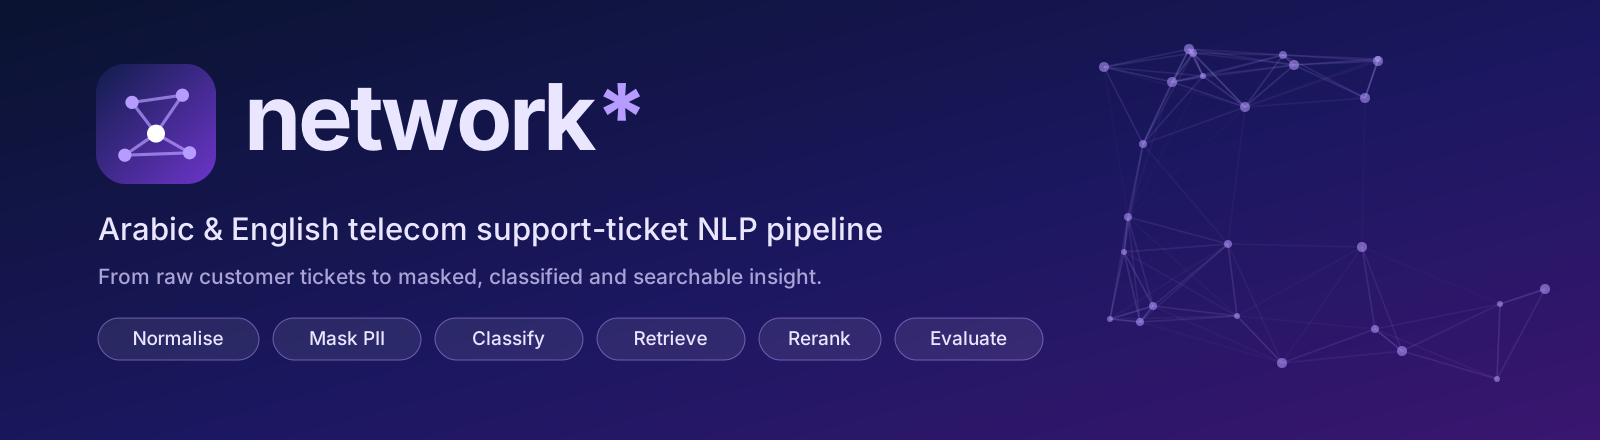


**Contents**

1. Text preprocessing and tokenizer audit
2. Attention mechanics and Arabic model comparison
3. Topic classification (fine-tuning CAMeLBERT)
4. Token alignment for NER
5. Arabic normalisation and segmentation
6. Semantic retrieval and reranking
7. Evaluation and error analysis

**Stack:** Hugging Face Transformers, PyTorch, Datasets, scikit-learn, Sentence-Transformers, FAISS, pandas, matplotlib.

**Models:** `distilbert-base-multilingual-cased`, `bert-base-multilingual-cased`, `CAMeL-Lab/bert-base-arabic-camelbert-mix`, `paraphrase-multilingual-MiniLM-L12-v2`, `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1`.

> **Note:** All datasets here are small, hand-written samples used to demonstrate each step. Scores and metrics are illustrative and are not benchmark results.

---
## 1. Text preprocessing and tokenizer audit

Clean mixed Arabic/English tickets, mask personal data, then measure how well a multilingual tokenizer handles each language.

### 1.1 Install and import libraries

In [1]:
!pip install -q transformers pandas matplotlib

In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

### 1.2 Create the dataset

In [4]:
# Project Name
project_name = "Rama"

# Project Dataset
data = {
    "language": ["ar", "ar", "ar", "ar", "en", "en"],
    "text": [
        "السَّلام عليكم، أنا خالد العتيبي، رقم جوالي 0555123454 وأرغب بإلغاء باقة الإنترنت",
        "أنا سارة الغامدي، هويتي الوطنية 1098765432 والآيبان SA0380000000608010167519 لم يصلني المبلغ المسترجع من الفاتورة",
         "تطبيق MyTelecom يعطيني خطأ عند الدخول والســـرعة ضعيفة، تواصلوا معي على sara.k@example.com",
        "طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد أحد على بلاغي في فرع الرياض",
        "Hi, I'm Michael Brown. Please call me on 055 123 4567 because my router keeps disconnecting",
        "I was charged twice on 2025-03-14 for my data plan. Email me at m.brown@example.com, ID 1087654321"
    ]
}


# Create DataFrame
df = pd.DataFrame(data)

# Confirmation
print(" Project:", project_name)
print(" Dataset created successfully!")

# Display Dataset
display(df)


 Project: Rama
 Dataset created successfully!


,language,text
0,ar,السَّلام عليكم، أنا خالد العتيبي، رقم جوالي 05...
1,ar,أنا سارة الغامدي، هويتي الوطنية 1098765432 وال...
2,ar,تطبيق MyTelecom يعطيني خطأ عند الدخول والســـر...
3,ar,طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد...
4,en,"Hi, I'm Michael Brown. Please call me on 055 1..."
5,en,I was charged twice on 2025-03-14 for my data ...


### 1.3 Text normalisation

In [5]:
import re
from IPython.display import HTML, display

def normalize(text):
    text = str(text).replace("،", "").replace(",", "")
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].apply(normalize)

print("✅ Normalisation Completed!")
display(HTML(df[["text", "clean_text"]].to_html(index=False)))

✅ Normalisation Completed!


text,clean_text
السَّلام عليكم، أنا خالد العتيبي، رقم جوالي 0555123454 وأرغب بإلغاء باقة الإنترنت,السَّلام عليكم أنا خالد العتيبي رقم جوالي 0555123454 وأرغب بإلغاء باقة الإنترنت
أنا سارة الغامدي، هويتي الوطنية 1098765432 والآيبان SA0380000000608010167519 لم يصلني المبلغ المسترجع من الفاتورة,أنا سارة الغامدي هويتي الوطنية 1098765432 والآيبان SA0380000000608010167519 لم يصلني المبلغ المسترجع من الفاتورة
تطبيق MyTelecom يعطيني خطأ عند الدخول والســـرعة ضعيفة، تواصلوا معي على sara.k@example.com,تطبيق MyTelecom يعطيني خطأ عند الدخول والســـرعة ضعيفة تواصلوا معي على sara.k@example.com
طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد أحد على بلاغي في فرع الرياض,طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد أحد على بلاغي في فرع الرياض
"Hi, I'm Michael Brown. Please call me on 055 123 4567 because my router keeps disconnecting",Hi I'm Michael Brown. Please call me on 055 123 4567 because my router keeps disconnecting
"I was charged twice on 2025-03-14 for my data plan. Email me at m.brown@example.com, ID 1087654321",I was charged twice on 2025-03-14 for my data plan. Email me at m.brown@example.com ID 1087654321


### 1.4 PII masking

In [6]:
# 📝 Add Sample Personal Information
df.loc[0, "clean_text"] = (
    "السَّلام عليكم، أنا خالد العتيبي، رقم جوالي 0555123454 وأرغب بإلغاء باقة الإنترنت"
    " على الرقم 0551234567 أو email@example.com"
)

df.loc[1, "clean_text"] = (
    "أنا سارة الغامدي، هويتي الوطنية 1098765432 والآيبان SA0380000000608010167519 لم يصلني المبلغ المسترجع من الفاتورة"
    " راسلوني على test@gmail.com أو 0509876543"
)

df.loc[2, "clean_text"] = (
    "تطبيق MyTelecom يعطيني خطأ عند الدخول والســـرعة ضعيفة، تواصلوا معي على sara.k@example.com"
    " أو على الرقم 0509876543"
)

df.loc[3, "clean_text"] = (
    "طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد أحد على بلاغي في فرع الرياض"
    " راسلوني على test@gmail.com أو 0509876543"
)


# 🛡️ Define Masking Function
def mask_pii(text):
    text = str(text)

    # Mask Email Addresses
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b', '[EMAIL]', text)

    # Mask Saudi Mobile Numbers
    text = re.sub(r'\b05\d{8}\b', '[PHONE]', text)

    return text

# 🔒 Apply Masking
df["masked_text"] = df["clean_text"].apply(mask_pii)

# 📊 Display Results
display(df[["clean_text", "masked_text"]])


,clean_text,masked_text
0,السَّلام عليكم، أنا خالد العتيبي، رقم جوالي 05...,السَّلام عليكم، أنا خالد العتيبي، رقم جوالي [P...
1,أنا سارة الغامدي، هويتي الوطنية 1098765432 وال...,أنا سارة الغامدي، هويتي الوطنية 1098765432 وال...
2,تطبيق MyTelecom يعطيني خطأ عند الدخول والســـر...,تطبيق MyTelecom يعطيني خطأ عند الدخول والســـر...
3,طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد...,طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد...
4,Hi I'm Michael Brown. Please call me on 055 12...,Hi I'm Michael Brown. Please call me on 055 12...
5,I was charged twice on 2025-03-14 for my data ...,I was charged twice on 2025-03-14 for my data ...


### 1.5 Tokenisation

In [7]:
# 🤖 Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-multilingual-cased"
)

# 🔤 Apply Tokenisation
df["tokens"] = df["masked_text"].apply(
    tokenizer.tokenize
)

# 📊 Display Results
print("✅ Tokenisation Completed!")
display(df[["masked_text", "tokens"]])


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

✅ Tokenisation Completed!


,masked_text,tokens
0,السَّلام عليكم، أنا خالد العتيبي، رقم جوالي [P...,"[ال, ##س, ##َّ, ##لام, علي, ##كم, ،, أن, ##ا, ..."
1,أنا سارة الغامدي، هويتي الوطنية 1098765432 وال...,"[أن, ##ا, س, ##ارة, ال, ##غا, ##مد, ##ي, ،, هو..."
2,تطبيق MyTelecom يعطيني خطأ عند الدخول والســـر...,"[ت, ##طبيق, My, ##T, ##ele, ##com, ي, ##ع, ##ط..."
3,طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد...,"[طلب, ال, ##ص, ##يان, ##ة, رقم, 202, ##41, ##2..."
4,Hi I'm Michael Brown. Please call me on 055 12...,"[Hi, I, ', m, Michael, Brown, ., Please, call,..."
5,I was charged twice on 2025-03-14 for my data ...,"[I, was, charged, twice, on, 2025, -, 03, -, 1..."


### 1.6 Token count

In [9]:
#  Count Tokens
df["token_count"] = df["tokens"].apply(len)

#  Display Results
print("✅ Token Count Completed!")
display(df[["masked_text", "tokens", "token_count"]])


✅ Token Count Completed!


,masked_text,tokens,token_count
0,السَّلام عليكم، أنا خالد العتيبي، رقم جوالي [P...,"[ال, ##س, ##َّ, ##لام, علي, ##كم, ،, أن, ##ا, ...",51
1,أنا سارة الغامدي، هويتي الوطنية 1098765432 وال...,"[أن, ##ا, س, ##ارة, ال, ##غا, ##مد, ##ي, ،, هو...",66
2,تطبيق MyTelecom يعطيني خطأ عند الدخول والســـر...,"[ت, ##طبيق, My, ##T, ##ele, ##com, ي, ##ع, ##ط...",50
3,طلب الصيانة رقم 2024123456 تأخر 12 يوم ولم يرد...,"[طلب, ال, ##ص, ##يان, ##ة, رقم, 202, ##41, ##2...",44
4,Hi I'm Michael Brown. Please call me on 055 12...,"[Hi, I, ', m, Michael, Brown, ., Please, call,...",23
5,I was charged twice on 2025-03-14 for my data ...,"[I, was, charged, twice, on, 2025, -, 03, -, 1...",30


### 1.7 Tokenizer audit

Fertility (tokens per word), p95 sequence length and UNK rate.

In [10]:
# 📊 Calculate Fertility
df["fertility"] = df["token_count"] / df["masked_text"].str.split().str.len()

# 🔍 Calculate UNK Rate
total = df["token_count"].sum()
unknown = sum(t.count(tokenizer.unk_token) for t in df["tokens"])

# ✅ Display Results
print("🧪 Project:", project_name)

print("\n🌐 Average Fertility:")
print(df.groupby("language")["fertility"].mean().round(2))

print("\n📏 p95 Sequence Length:", round(df["token_count"].quantile(0.95), 2))
print("🔍 UNK Rate:", round(unknown / total, 4) if total else 0)

print("✅ Tokenizer Audit Completed!")


🧪 Project: Rama

🌐 Average Fertility:
language
ar    2.95
en    1.66
Name: fertility, dtype: float64

📏 p95 Sequence Length: 62.25
🔍 UNK Rate: 0.0
✅ Tokenizer Audit Completed!


---
## 2. Attention mechanics and Arabic model comparison

Build attention from scratch on a real Arabic ticket and compare a multilingual model against an Arabic-specific one.

### 2.1 Setup

In [11]:
import torch
import matplotlib.pyplot as plt

# ✏️ Change the text here
text = "الإنترنت مقطوع عندي من الصباح ولم تعد الخدمة حتى الآن. حاولت إعادة تشغيل الجهاز أكثر من مرة دون فائدة، وتواصلت مع خدمة العملاء لكن لم يصلني أي رد. أرجو معالجة المشكلة في أقرب وقت لأن عملي يعتمد على الاتصال بشكل كامل."

# Split text into words
words = text.split()

# Reproducible results
torch.manual_seed(42)

print("✅ Lab 2 Ready")
print("Project: Bayan")
print("Text:", text)
print("Words:", words)
print("Word count:", len(words))


✅ Lab 2 Ready
Project: Bayan
Text: الإنترنت مقطوع عندي من الصباح ولم تعد الخدمة حتى الآن. حاولت إعادة تشغيل الجهاز أكثر من مرة دون فائدة، وتواصلت مع خدمة العملاء لكن لم يصلني أي رد. أرجو معالجة المشكلة في أقرب وقت لأن عملي يعتمد على الاتصال بشكل كامل.
Words: ['الإنترنت', 'مقطوع', 'عندي', 'من', 'الصباح', 'ولم', 'تعد', 'الخدمة', 'حتى', 'الآن.', 'حاولت', 'إعادة', 'تشغيل', 'الجهاز', 'أكثر', 'من', 'مرة', 'دون', 'فائدة،', 'وتواصلت', 'مع', 'خدمة', 'العملاء', 'لكن', 'لم', 'يصلني', 'أي', 'رد.', 'أرجو', 'معالجة', 'المشكلة', 'في', 'أقرب', 'وقت', 'لأن', 'عملي', 'يعتمد', 'على', 'الاتصال', 'بشكل', 'كامل.']
Word count: 41


### 2.2 Scaled dot-product attention

In [12]:
import torch.nn.functional as F

# 🔢 Create sample Q, K, V
q = torch.randn(1, 1, len(words), 8)
k = torch.randn(1, 1, len(words), 8)
v = torch.randn(1, 1, len(words), 8)

# 🧠 Calculate Attention
scores = (q @ k.transpose(-2, -1)) / (8 ** 0.5)
weights = torch.softmax(scores, dim=-1)
output = weights @ v

# ✅ Compare with PyTorch
expected = F.scaled_dot_product_attention(q, k, v)
torch.testing.assert_close(output, expected, atol=1e-6, rtol=1e-6)

print("✅ Attention Test PASSED!")
print("Words:", words)
print("\nAttention Matrix:")
print(weights[0, 0].round(decimals=2))


✅ Attention Test PASSED!
Words: ['الإنترنت', 'مقطوع', 'عندي', 'من', 'الصباح', 'ولم', 'تعد', 'الخدمة', 'حتى', 'الآن.', 'حاولت', 'إعادة', 'تشغيل', 'الجهاز', 'أكثر', 'من', 'مرة', 'دون', 'فائدة،', 'وتواصلت', 'مع', 'خدمة', 'العملاء', 'لكن', 'لم', 'يصلني', 'أي', 'رد.', 'أرجو', 'معالجة', 'المشكلة', 'في', 'أقرب', 'وقت', 'لأن', 'عملي', 'يعتمد', 'على', 'الاتصال', 'بشكل', 'كامل.']

Attention Matrix:
tensor([[0.0500, 0.0100, 0.0300,  ..., 0.0100, 0.0500, 0.0000],
        [0.0200, 0.0100, 0.0100,  ..., 0.0100, 0.0000, 0.0400],
        [0.0200, 0.0300, 0.0200,  ..., 0.0100, 0.0700, 0.0000],
        ...,
        [0.0100, 0.0100, 0.0100,  ..., 0.0000, 0.0700, 0.0200],
        [0.0300, 0.0300, 0.0200,  ..., 0.0200, 0.0200, 0.0700],
        [0.1000, 0.0400, 0.0400,  ..., 0.0100, 0.0300, 0.0200]])


### 2.3 Multi-head attention

In [13]:

import torch.nn as nn

# 🧠 Create Multi-Head Attention
mha = nn.MultiheadAttention(
    embed_dim=768,
    num_heads=12,
    batch_first=True
)

# 🔢 Create sample embeddings
x = torch.randn(1, len(words), 768)

# ✅ Run Attention
output, weights = mha(x, x, x)

# 📊 Count Parameters
params = sum(p.numel() for p in mha.parameters())

print("✅ Multi-Head Attention Ready!")
print("Words:", words)
print("Number of Heads:", mha.num_heads)
print("Head Dimension:", 768 // mha.num_heads)
print("Output Shape:", tuple(output.shape))
print("MHA Parameters:", f"{params:,}")


✅ Multi-Head Attention Ready!
Words: ['الإنترنت', 'مقطوع', 'عندي', 'من', 'الصباح', 'ولم', 'تعد', 'الخدمة', 'حتى', 'الآن.', 'حاولت', 'إعادة', 'تشغيل', 'الجهاز', 'أكثر', 'من', 'مرة', 'دون', 'فائدة،', 'وتواصلت', 'مع', 'خدمة', 'العملاء', 'لكن', 'لم', 'يصلني', 'أي', 'رد.', 'أرجو', 'معالجة', 'المشكلة', 'في', 'أقرب', 'وقت', 'لأن', 'عملي', 'يعتمد', 'على', 'الاتصال', 'بشكل', 'كامل.']
Number of Heads: 12
Head Dimension: 64
Output Shape: (1, 41, 768)
MHA Parameters: 2,362,368


### 2.4 Parameter audit: mBERT vs CAMeLBERT

In [14]:
from transformers import AutoModel

models = {
    "mBERT": "bert-base-multilingual-cased",
    "CAMeLBERT": "CAMeL-Lab/bert-base-arabic-camelbert-mix"
}

for name, model_id in models.items():
    model = AutoModel.from_pretrained(model_id)

    total = sum(p.numel() for p in model.parameters())
    embeddings = sum(p.numel() for p in model.embeddings.parameters())

    print(f"\n🤖 {name}")
    print(f"Total Parameters: {total/1e6:.1f}M")
    print(f"Embeddings: {embeddings/1e6:.1f}M")

    del model

print("\n✅ Parameter Audit Completed!")


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🤖 mBERT
Total Parameters: 177.9M
Embeddings: 92.2M


... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🤖 CAMeLBERT
Total Parameters: 109.1M
Embeddings: 23.4M

✅ Parameter Audit Completed!


### 2.5 Causal mask

In [15]:
# ✏️ Change the text here
test_text = "الشبكة ضعيفة جدًا في منطقتنا منذ أمس، والمكالمات تنقطع باستمرار ولا أستطيع تصفح الإنترنت بشكل طبيعي. جربت تغيير الشريحة وإعادة تشغيل الجوال لكن المشكلة ما زالت موجودة. أتمنى من الشركة إصلاح العطل قريبًا وتعويضنا عن أيام الانقطاع."
test_words = test_text.split()

# 🛡️ Create Causal Mask
n = len(test_words)
mask = torch.tril(torch.ones(n, n, dtype=torch.bool))

# 🧠 Apply Mask
scores = torch.randn(n, n)
attention = torch.softmax(
    scores.masked_fill(~mask, float("-inf")), dim=-1
)

# ✅ Display Results
print("✅ Causal Mask Applied!")
print("Words:", test_words)
print("\nCausal Mask:")
print(mask.int())
print("\nAttention Weights:")
print(attention.round(decimals=2))


✅ Causal Mask Applied!
Words: ['الشبكة', 'ضعيفة', 'جدًا', 'في', 'منطقتنا', 'منذ', 'أمس،', 'والمكالمات', 'تنقطع', 'باستمرار', 'ولا', 'أستطيع', 'تصفح', 'الإنترنت', 'بشكل', 'طبيعي.', 'جربت', 'تغيير', 'الشريحة', 'وإعادة', 'تشغيل', 'الجوال', 'لكن', 'المشكلة', 'ما', 'زالت', 'موجودة.', 'أتمنى', 'من', 'الشركة', 'إصلاح', 'العطل', 'قريبًا', 'وتعويضنا', 'عن', 'أيام', 'الانقطاع.']

Causal Mask:
tensor([[1, 0, 0,  ..., 0, 0, 0],
        [1, 1, 0,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 1, 0, 0],
        [1, 1, 1,  ..., 1, 1, 0],
        [1, 1, 1,  ..., 1, 1, 1]], dtype=torch.int32)

Attention Weights:
tensor([[1.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
        [0.2200, 0.7800, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
        [0.1400, 0.5000, 0.3600,  ..., 0.0000, 0.0000, 0.0000],
        ...,
        [0.1100, 0.0100, 0.0000,  ..., 0.0200, 0.0000, 0.0000],
        [0.0200, 0.0300, 0.0100,  ..., 0.0400, 0.0000, 0.0000],
        [0.0200, 0.0200,

### 2.6 Attention map

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


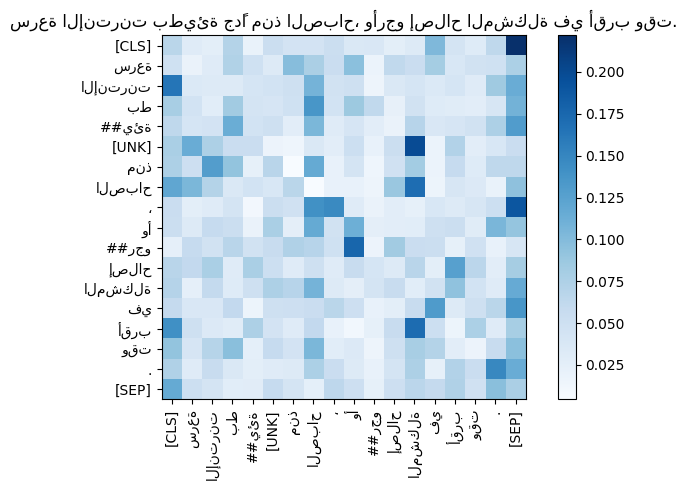

✅ Attention Map Completed!


In [16]:

from transformers import AutoTokenizer, AutoModel

# 🤖 Load Model
name = "CAMeL-Lab/bert-base-arabic-camelbert-mix"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(
    name, attn_implementation="eager"
).eval()

# ✏️ Change the text here
text = "سرعة الإنترنت بطيئة جدًا منذ الصباح، وأرجو إصلاح المشكلة في أقرب وقت."

# 🧠 Calculate Attention
inputs = tok(text, return_tensors="pt")

with torch.no_grad():
    att = model(**inputs, output_attentions=True).attentions

# 📊 Display Attention Map
tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])

plt.figure(figsize=(7, 5))
plt.imshow(att[0][0, 0].numpy(), cmap="Blues")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.title(text)
plt.colorbar()
plt.tight_layout()
plt.show()

print("✅ Attention Map Completed!")


### 2.7 PAD leak detection

In [17]:
# ✏️ Change padding length here
pad_length = 16

# 🔤 Use Text from Code 6
size = max(pad_length, len(tok.encode(text)) + 4)
inputs = tok(text, return_tensors="pt",
             padding="max_length", max_length=size)

# 🧠 Compare With / Without Mask
with torch.no_grad():
    with_mask = model(**inputs, output_attentions=True).attentions[0][0, 0]
    without_mask = model(
        input_ids=inputs["input_ids"], output_attentions=True
    ).attentions[0][0, 0]

# 📊 Display Results
pads = inputs["attention_mask"][0] == 0
valid = ~pads

print("✅ PAD Leak Test Completed!")
print("PAD Count:", pads.sum().item())
print("With Mask:", round(with_mask[valid][:, pads].sum(-1).mean().item(), 4))
print("Without Mask:", round(without_mask[valid][:, pads].sum(-1).mean().item(), 4))


✅ PAD Leak Test Completed!
PAD Count: 4
With Mask: 0.0
Without Mask: 0.1166


### 2.8 Tokenizer comparison on Arabic text

In [18]:
from transformers import AutoTokenizer
for n in ["CAMeL-Lab/bert-base-arabic-camelbert-mix", "bert-base-multilingual-cased"]:
    print(n, AutoTokenizer.from_pretrained(n).tokenize(text))

CAMeL-Lab/bert-base-arabic-camelbert-mix ['سرعة', 'الإنترنت', 'بط', '##يئة', '[UNK]', 'منذ', 'الصباح', '،', 'وأ', '##رجو', 'إصلاح', 'المشكلة', 'في', 'أقرب', 'وقت', '.']


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

bert-base-multilingual-cased ['سر', '##عة', 'الإنترنت', 'ب', '##طي', '##ئة', 'ج', '##د', '##ًا', 'منذ', 'ال', '##صب', '##اح', '،', 'و', '##أ', '##رج', '##و', 'إ', '##صلاح', 'ال', '##م', '##شكلة', 'في', 'أ', '##قرب', 'وقت', '.']


---
## 3. Topic classification

Fine-tune CAMeLBERT to route tickets into five topics: outage, billing, slow internet, coverage and app services.

### 3.1 Install

In [19]:
!pip install -q transformers datasets scikit-learn pandas

### 3.2 Dataset and labels

In [20]:
import pandas as pd

# بيانات المشروع - يمكن تعديلها
data = {
    "citizen_id": [1, 1, 2, 3, 3, 4, 5, 5, 2, 4],

    "text": [
        "الإنترنت مقطوع عن المنزل منذ الصباح",
        "انقطعت الخدمة مرة أخرى",
        "الفاتورة مرتفعة بشكل غير مبرر",
        "سرعة الإنترنت بطيئة",
        "مشكلة في سرعة التحميل",
        "الشبكة ضعيفة في منطقتي",
        "لا أستطيع تسجيل الدخول إلى تطبيق الشركة",
        "التطبيق لا يعمل",
        "تم خصم مبلغ إضافي من رصيدي",
        "لا توجد تغطية داخل المبنى"
    ],
##outage
#billing
#slow_internet
#coverage
#app_services

    "topic": [
        "outage", "outage", "billing", "slow_internet",
        "slow_internet", "coverage", "app_services",
        "app_services", "billing", "coverage"
    ]
}

df = pd.DataFrame(data)

topics = sorted(df["topic"].unique())
label_map = {topic: i for i, topic in enumerate(topics)}
df["label"] = df["topic"].map(label_map)

print(df)
print("\nLabels:", label_map)


   citizen_id                                     text          topic  label
0           1      الإنترنت مقطوع عن المنزل منذ الصباح         outage      3
1           1                   انقطعت الخدمة مرة أخرى         outage      3
2           2            الفاتورة مرتفعة بشكل غير مبرر        billing      1
3           3                      سرعة الإنترنت بطيئة  slow_internet      4
4           3                    مشكلة في سرعة التحميل  slow_internet      4
5           4                   الشبكة ضعيفة في منطقتي       coverage      2
6           5  لا أستطيع تسجيل الدخول إلى تطبيق الشركة   app_services      0
7           5                          التطبيق لا يعمل   app_services      0
8           2               تم خصم مبلغ إضافي من رصيدي        billing      1
9           4                لا توجد تغطية داخل المبنى       coverage      2

Labels: {'app_services': 0, 'billing': 1, 'coverage': 2, 'outage': 3, 'slow_internet': 4}


### 3.3 Group-aware train/test split

Splitting by `citizen_id` keeps tickets from the same customer out of both sets, which prevents leakage.

In [21]:
from sklearn.model_selection import GroupShuffleSplit

# ✏️ يمكن تعديل القيم حسب
test_size = 0.30
random_state = 7
group_column = "citizen_id"

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=test_size,
    random_state=random_state
)

train_idx, test_idx = next(
    gss.split(df, groups=df[group_column])
)

train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

shared = set(train_df[group_column]) & set(test_df[group_column])

print("Train:", len(train_df))
print("Test:", len(test_df))
print("Shared Citizens:", shared)


Train: 6
Test: 4
Shared Citizens: set()


### 3.4 Tokenise and build datasets

In [22]:
from transformers import AutoTokenizer
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained("CAMeL-Lab/bert-base-arabic-camelbert-mix")

sample_text = "الإنترنت مقطوع عن المنزل منذ الصباح"

def prepare_data(data):
    tokens = tokenizer(data["text"].tolist(), padding=True, truncation=True)
    tokens["labels"] = data["label"].tolist()
    return Dataset.from_dict(tokens)

train_dataset = prepare_data(train_df)
test_dataset = prepare_data(test_df)

print("Tokens:", tokenizer.tokenize(sample_text))
print("Input IDs:", tokenizer.encode(sample_text))
print("✅ Dataset Ready!")
print("Train:", len(train_dataset), "| Test:", len(test_dataset))


Tokens: ['الإنترنت', 'مقط', '##وع', 'عن', 'المنزل', 'منذ', 'الصباح']
Input IDs: [2, 5865, 17650, 2095, 1955, 6125, 2837, 4235, 3]
✅ Dataset Ready!
Train: 6 | Test: 4


### 3.5 Load the model

In [23]:
from transformers import AutoModelForSequenceClassification

num_labels = len(topics)

model = AutoModelForSequenceClassification.from_pretrained(
    "CAMeL-Lab/bert-base-arabic-camelbert-mix",
    num_labels=num_labels
)

print("✅ Model Ready!")
print("Number of Labels:", num_labels)
print("Topics:", topics)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

✅ Model Ready!
Number of Labels: 5
Topics: ['app_services', 'billing', 'coverage', 'outage', 'slow_internet']


### 3.6 Train and evaluate

In [25]:
from transformers import TrainingArguments, Trainer

epochs = 5
batch_size = 4
learning_rate = 1e-5

args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=epochs,
    per_device_train_batch_size=batch_size,
    learning_rate=learning_rate,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

trainer.train()
print("✅ Training Complete!")
print(trainer.evaluate())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Training Complete!


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,2.148578,10


{'eval_loss': 2.14857816696167}


---
## 4. Token alignment for NER

Arabic words split into several subword tokens, so word-level labels must be aligned to tokens.

### 4.1 Word IDs and labels

In [29]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "CAMeL-Lab/bert-base-arabic-camelbert-mix"
)

words = ["قطع", "خالد", "الشرقية","اتصل", "احمد", "الدمام"]
labels = ["O", "B-PER", "B-LOC","O","B-PER", "B-LOC"]

tokens = tokenizer(words, is_split_into_words=True)

print("Tokens:", tokenizer.convert_ids_to_tokens(tokens["input_ids"]))
print("Word IDs:", tokens.word_ids())
print("Labels:", labels)


Tokens: ['[CLS]', 'قطع', 'خالد', 'الشرقية', 'اتصل', 'احمد', 'الدمام', '[SEP]']
Word IDs: [None, 0, 1, 2, 3, 4, 5, None]
Labels: ['O', 'B-PER', 'B-LOC', 'O', 'B-PER', 'B-LOC']


### 4.2 Prefixed words split into subwords

In [30]:
words = ["والدمام", "بالانترنت", "واسماء", "والاتصالات"]

tokens = tokenizer(words, is_split_into_words=True)

token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])

for token, word_id in zip(token_list, tokens.word_ids()):
    print(token, "→", word_id)


[CLS] → None
والدم → 0
##ام → 0
بالانت → 1
##رنت → 1
واسم → 2
##اء → 2
والاتصالات → 3
[SEP] → None


---
## 5. Arabic normalisation and segmentation

Unify letter variants and look at how clitics (و، ال) attach to words.

### 5.1 Letter normalisation

In [31]:
import re

def normalize_arabic(text):
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    return text

text = "الإنترنت مقطوع عن المنزل من الصباح"

print("Before:", text)
print("After :", normalize_arabic(text))


Before: الإنترنت مقطوع عن المنزل من الصباح
After : الانترنت مقطوع عن المنزل من الصباح


### 5.2 Clitic segmentation

In [32]:
text = "والإنترنت"

print("Original:", text)
print("Segmented: و + ال + إ + نترنت")


Original: والإنترنت
Segmented: و + ال + إ + نترنت


---
## 6. Semantic retrieval and reranking

Find similar past tickets with sentence embeddings and a FAISS index, then rerank candidates with a cross-encoder.

### 6.1 Install

In [33]:
!pip install -q sentence-transformers faiss-cpu


### 6.2 Embed tickets and build the FAISS index

In [34]:
from sentence_transformers import SentenceTransformer
import faiss

texts = [
       "الإنترنت مقطوع من البيت من الصباح",
        "انقطعت الخدمة مرة ثانية",
        "الفاتورة مرتفعة بشكل غير معقول",
        "الإنترنت سرعته بطيئة",
        "مشكلة في سرعة التحميل",
        "الشبكة ضعيفة في حارتي"
]

model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

embeddings = model.encode(texts)

index = faiss.IndexFlatL2(embeddings.shape[1])

index.add(embeddings)

print("عدد النصوص في FAISS:", index.ntotal)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

عدد النصوص في FAISS: 6


### 6.3 Search

In [35]:
query =   "الإنترنت سرعته بطيئة"

query_embedding = model.encode([query])

distances, indices = index.search(query_embedding, 2)

print("Query:", query)
print("Results:")

for i in indices[0]:
    print("-", texts[i])


Query: الإنترنت سرعته بطيئة
Results:
- الإنترنت سرعته بطيئة
- الشبكة ضعيفة في حارتي


### 6.4 Retrieval metrics

In [36]:
results = [
     "الإنترنت مقطوع من البيت من الصباح",
        "انقطعت الخدمة مرة ثانية",
        "الإنترنت سرعته بطيئة"
]

correct_answer =  "الإنترنت سرعته بطيئة"

rank = results.index(correct_answer) + 1

recall_at_10 = 1 if rank <= 10 else 0
mrr_at_10 = 1 / rank

print("Recall@10:", recall_at_10)
print("MRR@10:", mrr_at_10)


Recall@10: 1
MRR@10: 0.3333333333333333


### 6.5 Cross-encoder reranking

In [37]:
from sentence_transformers import CrossEncoder

query = "الكهرباء لا تعمل"

results = [
  "الإنترنت سرعته بطيئة",
        "مشكلة في سرعة التحميل",
        "الكهرباء لا تعمل"
]

reranker = CrossEncoder(
    "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"
)

pairs = [[query, text] for text in results]

scores = reranker.predict(pairs)

for text, score in zip(results, scores):
    print(round(float(score), 2), "→", text)


config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

-3.91 → الإنترنت سرعته بطيئة
-3.66 → مشكلة في سرعة التحميل
4.36 → الكهرباء لا تعمل


---
## 7. Evaluation and error analysis

Slice results by language, dialect and length, estimate uncertainty with a bootstrap confidence interval, and review errors.

### 7.1 Sliced evaluation

In [38]:
students = [
    {"language": "Arabic", "dialect": "UAE", "length": "Long", "correct": 0},
    {"language": "English", "dialect": "Standard", "length": "Long", "correct": 0},
    {"language": "Arabic", "dialect": "Saudi", "length": "Long", "correct": 1},
    {"language": "Arabic", "dialect": "Egyptian", "length": "Long", "correct": 0},
    {"language": "English", "dialect": "USA", "length": "Short", "correct": 1}
]

for student in students:
    print(
        student["language"],
        "|", student["dialect"],
        "|", student["length"],
        "| Correct:", student["correct"]
    )


Arabic | UAE | Long | Correct: 0
English | Standard | Long | Correct: 0
Arabic | Saudi | Long | Correct: 1
Arabic | Egyptian | Long | Correct: 0
English | USA | Short | Correct: 1


### 7.2 Bootstrap 95% confidence interval

In [39]:
import numpy as np
from sklearn.metrics import accuracy_score

y_true = np.array([1, 1, 1, 1, 0, 0, 0, 0])
y_pred = np.array([1, 1, 1, 1, 0, 1, 1, 1])

scores = []

for _ in range(1000):
    i = np.random.choice(len(y_true), len(y_true), replace=True)
    scores.append(accuracy_score(y_true[i], y_pred[i]))

print("95% CI:", np.percentile(scores, 2.5), "-", np.percentile(scores, 97.5))


95% CI: 0.25 - 1.0


### 7.3 Error analysis

In [40]:
errors = [
    ("الانترنت لا يعمل", "انقطاع الخدمة", "الانترنت يعمل"),
    ("الإنترنت مقطوع من البيت من الصباح",  "انقطعت الخدمة مرة ثانية", "الخدمة لا تعمل"),
    ( "الإنترنت سرعته بطيئة", "مشكلة في سرعة التحميل", "الشبكة ضعيفة ")

    ]

for text, actual, predicted in errors:
    print("البلاغ:", text)
    print("التصنيف الصحيح:", actual)
    print("توقع النموذج:", predicted)
    print("التقييم:", "صحيح" if actual == predicted else "خطأ")
    print("-" * 30)


البلاغ: الانترنت لا يعمل
التصنيف الصحيح: انقطاع الخدمة
توقع النموذج: الانترنت يعمل
التقييم: خطأ
------------------------------
البلاغ: الإنترنت مقطوع من البيت من الصباح
التصنيف الصحيح: انقطعت الخدمة مرة ثانية
توقع النموذج: الخدمة لا تعمل
التقييم: خطأ
------------------------------
البلاغ: الإنترنت سرعته بطيئة
التصنيف الصحيح: مشكلة في سرعة التحميل
توقع النموذج: الشبكة ضعيفة 
التقييم: خطأ
------------------------------
